Remake the T-S diagram with streamtube results, but make axes with the difference in T and S on the Nordic and Subpolar sides of the ridge. Then do the same for CMIP6 models.  

In [1]:
import intake
import xarray as xr
import numpy as np
import dask
import time
import pickle


In [134]:
import intake
import xarray as xr
import numpy as np
import dask
import time
import pickle
from xmip.preprocessing import combined_preprocessing
import warnings
import logging

warnings.filterwarnings('ignore', message='Could not determine bucket type')
warnings.filterwarnings('ignore', message='In a future version of xarray')
logging.getLogger('gcsfs').setLevel(logging.ERROR)
logging.getLogger('fsspec').setLevel(logging.ERROR)
logging.getLogger('google').setLevel(logging.ERROR)

dask.config.set(scheduler='threads', num_workers=4)

# ============================================================================
# CONFIGURATION
# ============================================================================

locations = {
    'SPSide_DS': {'lat': 65.0, 'lon': 330.0},
    'SPSide_FSC': {'lat': 62, 'lon': 350.0},
    'DenStrait': {'lat': 67.5, 'lon': 334},
    'FSChannel': {'lat': 64, 'lon': 356}
}

periods = {
    'period1_1950-1969': slice(1200, 1440),
    'period2_1995-2014': slice(1740, 1980),
}

z_kwargs = {
    'consolidated': True,
    'decode_times': False,
}

output_file = 'cmip6_profiles_all.pkl'

# ============================================================================
# HELPER FUNCTIONS
# ============================================================================

def find_nearest_point(ds, target_lat, target_lon):
    #Find the name of the longitude variable in an xarray dataset:
    lat_name = next((n for n in ['lat', 'latitude', 'nav_lat', 'lats'] if n in ds.coords or n in ds.data_vars), None)
    lon_name = next((n for n in ['lon', 'longitude', 'nav_lon', 'lons'] if n in ds.coords or n in ds.data_vars), None)
    
    if lat_name is None or lon_name is None:
        raise ValueError("Could not find lat/lon coordinates")
    
    lat = ds[lat_name].values
    lon = ds[lon_name].values
     
    # Compute distance to all grid points (approximate relative to full spherical correction)
    R_EARTH = 6371.0  # km
    dlat = np.radians(lat - target_lat)
    dlon = np.radians(lon - target_lon) * np.cos(np.radians(target_lat))
    distance = R_EARTH * np.sqrt(dlat**2 + dlon**2)

    distance = np.sqrt((lat - target_lat)**2 + (lon - target_lon)**2)
    
    # Find minimum
    nearest_idx = np.argmin(distance)
    indices = np.unravel_index(nearest_idx, lat.shape)
    
    return indices[0], indices[1], float(lat[indices]), float(lon[indices])


def extract_profiles_single_model(dset_dict_key, dset, locations, periods, model_index, total_models):
    """Extract profiles for ONE model at ALL locations."""
    model_name = dset_dict_key.split(".")[2]
    
    print(f"\n{'='*70}")
    print(f"MODEL {model_index + 1}/{total_models}: {model_name}")
    print(f"{'='*70}")
    
    tic_model = time.perf_counter()
    profiles = {model_name: {}}
    
    # Get depth coordinate
    print(f"  [TIMER {time.time():.1f}] Getting depth coordinate...")
    if 'lev_bounds' in dset:
        depths = dset['lev_bounds'].mean(dim='bnds').values
    elif 'lev' in dset:
        depths = dset['lev'].values
    elif 'rho' in dset:
        raise ValueError(f"Model uses density coordinate (rho), not depth. Skipping.")
    else:
        raise ValueError("Could not identify depth coordinate")
    
    print(f"  [TIMER {time.time():.1f}] Depth coordinate retrieved: {len(depths)} levels")
    
    # PHASE 1: Find nearest points for ALL locations
    tic_phase1 = time.perf_counter()
    print(f"  [TIMER {time.time():.1f}] PHASE 1: Finding nearest points for {len(locations)} locations...")
    
    nearest_points = {}
    for loc_name, coords in locations.items():
        try:
            y, x, actual_lat, actual_lon = find_nearest_point(dset, coords['lat'], coords['lon'])
            
            print(
                f"    {loc_name}: target=({coords['lat']:.2f}, {coords['lon']:.2f}) → "
                f"actual=({actual_lat:.2f}, {actual_lon:.2f}) [y={y}, x={x}]"
            )
            
            profiles[model_name][loc_name] = {
                'target_lat': coords['lat'],
                'target_lon': coords['lon'],
                'actual_lat': actual_lat,
                'actual_lon': actual_lon,
                'y': y,
                'x': x,
            }
            
            nearest_points[loc_name] = (y, x)
            
        except Exception as e:
            print(f"    ❌ {loc_name} failed: {type(e).__name__}: {e}")
            nearest_points[loc_name] = None
    
    toc_phase1 = time.perf_counter()
    print(f"  [TIMER {time.time():.1f}] PHASE 1 complete: {toc_phase1 - tic_phase1:.2f}s")
    
    # PHASE 2: Build lazy operations for ALL locations and periods
    tic_phase2 = time.perf_counter()
    print(f"  [TIMER {time.time():.1f}] PHASE 2: Building computation graph...")
    
    lazy_tasks = {}
    
    for loc_name, (y, x) in nearest_points.items():
        if (y, x) is None:
            continue
        
        for period_name, time_slice in periods.items():
            ds_period = dset.isel(time=time_slice)
            
            for var in ['thetao', 'so']:
                if var in ds_period:
                    lazy_profile = ds_period[var].isel(y=y, x=x).mean(dim='time')
                    lazy_tasks[(loc_name, period_name, var)] = lazy_profile
    
    toc_phase2 = time.perf_counter()
    print(f"  [TIMER {time.time():.1f}] PHASE 2 complete: {toc_phase2 - tic_phase2:.2f}s | Built {len(lazy_tasks)} tasks")
    
    # PHASE 3: Compute ALL at once
    tic_phase3 = time.perf_counter()
    print(f"  [TIMER {time.time():.1f}] PHASE 3: Computing {len(lazy_tasks)} profiles...")
    
    if lazy_tasks:
        task_keys = list(lazy_tasks.keys())
        task_arrays = list(lazy_tasks.values())
        
        tic_compute = time.perf_counter()
        print(f"  [TIMER {time.time():.1f}] Starting dask.compute()...")
        computed_results = dask.compute(*task_arrays)
        toc_compute = time.perf_counter()
        print(f"  [TIMER {time.time():.1f}] dask.compute() complete: {toc_compute - tic_compute:.2f}s")
        
        for (loc_name, period_name, var), result in zip(task_keys, computed_results):
            if period_name not in profiles[model_name][loc_name]:
                profiles[model_name][loc_name][period_name] = {'depth': depths}
            
            profile_values = result.squeeze().values
            profiles[model_name][loc_name][period_name][var] = profile_values
            
            n_valid = np.sum(~np.isnan(profile_values))
            n_total = len(profile_values)
            print(f"      {loc_name} / {period_name} / {var}: {n_valid}/{n_total} valid depths")
    
    toc_phase3 = time.perf_counter()
    print(f"  [TIMER {time.time():.1f}] PHASE 3 complete: {toc_phase3 - tic_phase3:.2f}s")
    
    toc_model = time.perf_counter()
    print(f"  [TIMER {time.time():.1f}] MODEL TOTAL TIME: {toc_model - tic_model:.2f}s ({(toc_model - tic_model)/60:.2f} min)")
    
    return profiles


def save_profiles(profiles, output_file):
    """Save profiles to pickle file."""
    with open(output_file, 'wb') as f:
        pickle.dump(profiles, f)
    print(f"✓ Saved profiles to {output_file}")


def load_existing_profiles(output_file):
    """Load existing profiles from file if it exists."""
    import os
    if os.path.exists(output_file):
        print(f"Loading existing profiles from {output_file}...")
        with open(output_file, 'rb') as f:
            return pickle.load(f)
    return {}


# ============================================================================
# FULL WORKFLOW: ALL MODELS FROM CATALOG
# ============================================================================

print("="*70)
print("CMIP6 PROFILES EXTRACTION - FULL WORKFLOW")
print("="*70)
print(f"Periods: 1950-1969 and 1995-2014")
print(f"Locations: {len(locations)} - {list(locations.keys())}\n")

tic_total = time.perf_counter()
print(f"[TIMER {time.time():.1f}] Workflow start")

# Load catalog
print(f"[TIMER {time.time():.1f}] Loading catalog...")
url = "https://storage.googleapis.com/cmip6/pangeo-cmip6.json"
col = intake.open_esm_datastore(url)

query = dict(
    experiment_id=['historical'],
    table_id='Omon',
    member_id='r1i1p1f1',
    variable_id=['thetao', 'so'],
    grid_label='gn',
)

cat = col.search(**query)
all_models = sorted(cat.df.source_id.unique())

print(f"[TIMER {time.time():.1f}] Found {len(all_models)} models in catalog")
print(f"Models: {all_models}\n")

# Load existing profiles and determine which to process
all_profiles = load_existing_profiles(output_file)
already_processed = set(all_profiles.keys())
models_to_process = [m for m in all_models if m not in already_processed]

print(f"Already processed: {len(already_processed)} models")
print(f"To process: {len(models_to_process)} models\n")

if len(models_to_process) == 0:
    print("All models already processed! Exiting.")
    toc_total = time.perf_counter()
    print(f"\nTotal time: {toc_total - tic_total:.2f}s ({(toc_total - tic_total)/60:.2f} minutes)")
else:
    # Process each model
    for model_idx, model in enumerate(models_to_process):
        
        try:
            print(f"[TIMER {time.time():.1f}] Loading dataset for {model}...")
            cat_model = cat.search(source_id=model)
            
            with dask.config.set(**{'array.slicing.split_large_chunks': True}):
                dset_dict = cat_model.to_dataset_dict(
                    zarr_kwargs=z_kwargs,
                    preprocess=combined_preprocessing,
                    progressbar=False,
                    skip_on_error=True
                )
            
            if not dset_dict:
                print(f"[TIMER {time.time():.1f}] ⚠ No datasets loaded for {model}")
                continue
            
            # Get the dataset key
            dset_key = list(dset_dict.keys())[0]
            dset = dset_dict[dset_key]
            
            print(f"[TIMER {time.time():.1f}] Dataset loaded: {dict(dset.dims)}")
            
            # Extract profiles
            model_profiles = extract_profiles_single_model(
                dset_key,
                dset,
                locations,
                periods,
                model_idx,
                len(models_to_process)
            )
            
            # Append to all profiles
            all_profiles.update(model_profiles)
            
            # Save after each model
            print(f"[TIMER {time.time():.1f}] Saving progress...")
            save_profiles(all_profiles, output_file)
            print(f"[TIMER {time.time():.1f}] ✓ {model} complete. Total models saved: {len(all_profiles)}\n")
            
        except Exception as e:
            print(f"[TIMER {time.time():.1f}] ❌ MODEL FAILED: {model}")
            print(f"   {type(e).__name__}: {e}")
            print(f"[TIMER {time.time():.1f}] Continuing to next model...\n")
            continue
    
    toc_total = time.perf_counter()
    
    print("\n" + "="*70)
    print("WORKFLOW COMPLETE")
    print("="*70)
    print(f"[TIMER {time.time():.1f}] Total elapsed time: {toc_total - tic_total:.2f}s ({(toc_total - tic_total)/60:.2f} minutes)")
    print(f"Models processed: {len(models_to_process)}")
    print(f"Total profiles saved: {len(all_profiles)} models")
    print(f"Output file: {output_file}")
    print("="*70)

CMIP6 PROFILES EXTRACTION - FULL WORKFLOW
Periods: 1950-1969 and 1995-2014
Locations: 4 - ['SPSide_DS', 'SPSide_FSC', 'DenStrait', 'FSChannel']

[TIMER 1793298472.8] Workflow start
[TIMER 1793298472.8] Loading catalog...
[TIMER 1793298480.4] Found 44 models in catalog
Models: ['ACCESS-CM2', 'ACCESS-ESM1-5', 'AWI-CM-1-1-MR', 'AWI-ESM-1-1-LR', 'BCC-CSM2-MR', 'BCC-ESM1', 'CAMS-CSM1-0', 'CAS-ESM2-0', 'CESM2', 'CESM2-FV2', 'CESM2-WACCM', 'CESM2-WACCM-FV2', 'CIESM', 'CMCC-CM2-HR4', 'CMCC-CM2-SR5', 'CMCC-ESM2', 'CanESM5', 'EC-Earth3', 'EC-Earth3-AerChem', 'EC-Earth3-CC', 'EC-Earth3-Veg-LR', 'FGOALS-f3-L', 'FGOALS-g3', 'FIO-ESM-2-0', 'GFDL-CM4', 'GFDL-ESM4', 'GISS-E2-1-G', 'GISS-E2-1-G-CC', 'ICON-ESM-LR', 'IPSL-CM5A2-INCA', 'IPSL-CM6A-LR', 'IPSL-CM6A-LR-INCA', 'MCM-UA-1-0', 'MIROC6', 'MPI-ESM-1-2-HAM', 'MPI-ESM1-2-HR', 'MPI-ESM1-2-LR', 'MRI-ESM2-0', 'NESM3', 'NorCPM1', 'NorESM2-LM', 'NorESM2-MM', 'SAM0-UNICON', 'TaiESM1']

Already processed: 0 models
To process: 44 models

[TIMER 1793298480.4]

/Users/jaimepalter/opt/anaconda3/envs/workenv/lib/python3.11/site-packages/xmip/preprocessing.py:229: UserWarning: CMIP.CSIRO-ARCCSS.ACCESS-CM2.historical.r1i1p1f1.Omon.gn.v20191108.so: Unit correction failed with: Cannot convert variables (1 sub-exception)
  warnings.warn(
/Users/jaimepalter/opt/anaconda3/envs/workenv/lib/python3.11/site-packages/xmip/preprocessing.py:229: UserWarning: CMIP.CSIRO-ARCCSS.ACCESS-CM2.historical.r1i1p1f1.Omon.gn.v20191108.thetao: Unit correction failed with: Cannot convert variables (1 sub-exception)
  warnings.warn(
/var/folders/h1/j3p_b5ts7314ws9g_tynb4g80000gn/T/ipykernel_51045/3620431218.py:268: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  print(f"[TIMER {time.time():.1f}] Dataset loaded: {dict(dset.dims)}")


[TIMER 1793298676.8] Dataset loaded: {'y': 300, 'x': 360, 'lev': 50, 'time': 1980, 'member_id': 1, 'dcpp_init_year': 1, 'vertex': 4, 'bnds': 2}

MODEL 1/44: ACCESS-CM2
  [TIMER 1793298676.8] Getting depth coordinate...
  [TIMER 1793298680.0] Depth coordinate retrieved: 50 levels
  [TIMER 1793298680.0] PHASE 1: Finding nearest points for 4 locations...
    SPSide_DS: target=(65.00, 330.00) → actual=(65.22, 330.50) [y=245, x=250]
    SPSide_FSC: target=(62.00, 350.00) → actual=(61.97, 349.50) [y=238, x=269]
    DenStrait: target=(67.50, 334.00) → actual=(67.43, 334.41) [y=250, x=254]
    FSChannel: target=(64.00, 356.00) → actual=(63.85, 355.50) [y=242, x=275]
  [TIMER 1793298710.5] PHASE 1 complete: 30.54s
  [TIMER 1793298710.5] PHASE 2: Building computation graph...
  [TIMER 1793298710.7] PHASE 2 complete: 0.13s | Built 16 tasks
  [TIMER 1793298710.7] PHASE 3: Computing 16 profiles...
  [TIMER 1793298710.7] Starting dask.compute()...


KeyboardInterrupt: 

Loaded 27 models

CAS-ESM2-0 | SPSide_DS | period1_1950-1969: 'thetao'
CAS-ESM2-0 | SPSide_DS | period2_1995-2014: 'thetao'
MPI-ESM1-2-HR | SPSide_DS | period1_1950-1969: 'so'
MPI-ESM1-2-HR | SPSide_DS | period2_1995-2014: 'so'
CAS-ESM2-0 | SPSide_FSC | period1_1950-1969: 'thetao'
CAS-ESM2-0 | SPSide_FSC | period2_1995-2014: 'thetao'
MPI-ESM1-2-HR | SPSide_FSC | period1_1950-1969: 'so'
MPI-ESM1-2-HR | SPSide_FSC | period2_1995-2014: 'so'
CAS-ESM2-0 | DenStrait | period1_1950-1969: 'thetao'
CAS-ESM2-0 | DenStrait | period2_1995-2014: 'thetao'
MPI-ESM1-2-HR | DenStrait | period1_1950-1969: 'so'
MPI-ESM1-2-HR | DenStrait | period2_1995-2014: 'so'
CAS-ESM2-0 | FSChannel | period1_1950-1969: 'thetao'
CAS-ESM2-0 | FSChannel | period2_1995-2014: 'thetao'
MPI-ESM1-2-HR | FSChannel | period1_1950-1969: 'so'
MPI-ESM1-2-HR | FSChannel | period2_1995-2014: 'so'


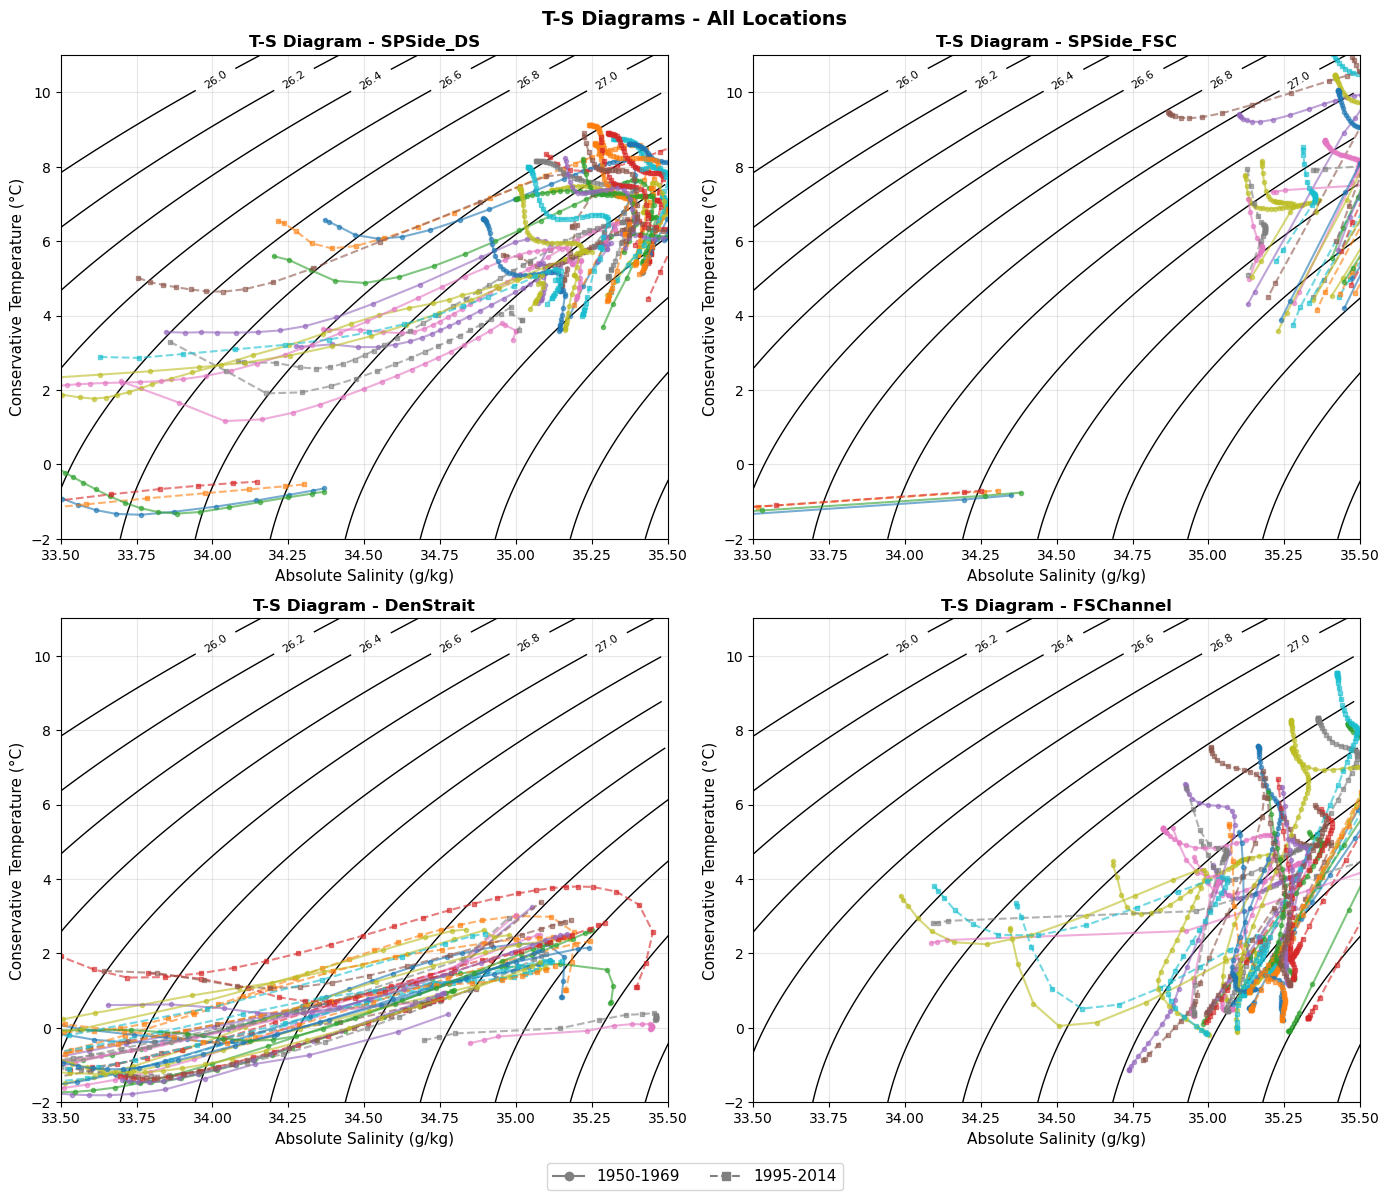

In [138]:
import gsw
import matplotlib.pyplot as plt
import numpy as np
import pickle
from matplotlib.lines import Line2D

output_file = 'cmip6_profiles_4locations.pkl'
with open(output_file, 'rb') as f:
    profiles = pickle.load(f)
print(f"Loaded {len(profiles)} models\n")

locations = {
    'SPSide_DS': {'lat': 65.0, 'lon': 330.0},
    'SPSide_FSC': {'lat': 62, 'lon': 350.0},
    'DenStrait': {'lat': 67.5, 'lon': 334},
    'FSChannel': {'lat': 64, 'lon': 356}
}
periods = {'early': 'period1_1950-1969', 'late': 'period2_1995-2014'}


def to_SA_CT(data, lat, lon):
    """Return (absolute salinity, conservative temperature) with NaNs removed."""
    pt = np.squeeze(data['thetao']).astype(float)
    sp = np.squeeze(data['so']).astype(float)
    depth = np.squeeze(data['depth']).astype(float)
    p = gsw.p_from_z(-depth, lat) 
   
    sa = gsw.SA_from_SP(sp, p, lon % 360, lat)
    ct = gsw.CT_from_pt(sa, pt)

    mask = ~(np.isnan(sa) | np.isnan(ct))
    return sa[mask], ct[mask]


fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

sal_range = np.linspace(33.5, 35.7, 100)
temp_range = np.linspace(-2, 11, 100)
Sal, Temp = np.meshgrid(sal_range, temp_range)
density = gsw.rho(Sal, Temp, 0) - 1000   # sigma0

for ax_idx, location in enumerate(locations):
    ax = axes[ax_idx]
    lat = locations[location]['lat']
    lon = locations[location]['lon']

    contours = ax.contour(Sal, Temp, density,
                          levels=np.arange(26, 28.5, 0.2),
                          colors='black', linewidths=1)
    ax.clabel(contours, fontsize=8, fmt='%0.1f')

    for model_name, model_data in profiles.items():
        if location not in model_data:
            continue

        for key, linestyle, marker in [('early', '-', 'o'), ('late', '--', 's')]:
            period = periods[key]
            if period not in model_data[location]:
                continue
            try:
                sal, temp = to_SA_CT(model_data[location][period], lat, lon)
            except Exception as e:
                print(f"{model_name} | {location} | {period}: {e}")
                continue

            ax.plot(sal, temp, linestyle=linestyle, marker=marker,
                    linewidth=1.5, alpha=0.6, markersize=3)

    ax.set_xlabel('Absolute Salinity (g/kg)', fontsize=11)
    ax.set_ylabel('Conservative Temperature (°C)', fontsize=11)
    ax.set_xlim(33.5, 35.5)
    ax.set_ylim(-2, 11)
    ax.set_title(f'T-S Diagram - {location}', fontsize=12, fontweight='bold')
    ax.grid(True, alpha=0.3)

legend_elements = [
    Line2D([0], [0], color='gray', linestyle='-', marker='o', label='1950-1969'),
    Line2D([0], [0], color='gray', linestyle='--', marker='s', label='1995-2014'),
]
fig.legend(handles=legend_elements, loc='lower center', ncol=2,
           fontsize=11, bbox_to_anchor=(0.5, -0.01))
fig.suptitle('T-S Diagrams - All Locations', fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0, 0.02, 1, 1])
plt.show()

In [ ]:
### DENMARK STRAIT Source water: Streamtube results and CMIP6 Sensitivity

import pickle
import numpy as np
import matplotlib.pyplot as plt
import gsw
from scipy import io as sio
from matplotlib.patches import Ellipse

# Load profiles
output_file = 'cmip6_profiles_4locations_all.pkl'
print(f"Loading profiles from {output_file}...")
with open(output_file, 'rb') as f:
    profiles = pickle.load(f)
print(f"Loaded {len(profiles)} models\n")

# Locations
locations = {
    'SPSide_DS': {'lat': 65.0, 'lon': 330.0},
    'SPSide_FSC': {'lat': 62, 'lon': 350.0},
    'DenStrait': {'lat': 67.5, 'lon': 334},
    'FSChannel': {'lat': 64, 'lon': 356}
}

# Load MATLAB data
mat_data = sio.loadmat('/Users/jaimepalter/Library/CloudStorage/OneDrive-UniversityofRhodeIsland/New Ideas/AMOC Lunch Bunch/DS_transport_dataSiCTi.mat')
Si = mat_data['Si']
CTi = mat_data['CTi']
Transport = mat_data['T']

location = 'DenStrait'
lat = locations[location]['lat']
lon = locations[location]['lon']


def profile_SA_CT(data, model_name, lat, lon):
    """
    Return depth, absolute salinity (g/kg), and conservative temperature (degC)
    for one profile. Applies the MRI-ESM2-0 fill mask (800 m test) first.
    """
    pt = np.squeeze(data['thetao']).astype(float)     # potential temp (degC)
    sp = np.squeeze(data['so']).astype(float)         # practical salinity
    depth = np.squeeze(data['depth']).astype(float)   # m, positive down

    if model_name == 'MRI-ESM2-0':
        i800 = np.argmin(np.abs(depth - 800))
        if np.abs(pt[i800] - 2) <= 0.1:               # fill value, so drop profile
            pt = np.full_like(pt, np.nan)
            sp = np.full_like(sp, np.nan)

   
    p = gsw.p_from_z(-depth, lat) 
    SA = gsw.SA_from_SP(sp, p, lon % 360, lat)        # absolute salinity (g/kg)
    CT = gsw.CT_from_pt(SA, pt)                       # conservative temperature (degC)
    return depth, SA, CT


fig, ax = plt.subplots(figsize=(10, 8))

# === Transport CONTOURS (behind everything) ===
Transmean = np.squeeze(Transport[:, :, :200].mean(axis=2))
cmap_discrete = plt.get_cmap('viridis', 10)
pcm = ax.pcolormesh(Si, CTi, Transmean / 1e6,
                    cmap=cmap_discrete,
                    alpha=0.4,
                    shading='auto',
                    zorder=0)


# === Potential density contours (sigma0, referenced to sea surface) ===
sal_range = np.linspace(34.4, 35.45, 100)     # absolute salinity (g/kg)
temp_range = np.linspace(-1, 6, 100)          # conservative temperature (degC)
Sal, Temp = np.meshgrid(sal_range, temp_range)
density = gsw.sigma0(Sal, Temp)

contours = ax.contour(Sal, Temp, density,
                      levels=np.arange(26, 28.5, 0.1),
                      colors='black', linewidths=1, zorder=2)
ax.clabel(contours, fontsize=8, fmt='%0.1f')

# Store early period data and model info
early_data = {}
model_list = []
model_counter = 1

# === Early period (circles) ===
for model_name, model_data in sorted(profiles.items()):
    if location not in model_data:
        continue
    try:
        data = model_data[location]['period1_1950-1969']
        depth, SA, CT = profile_SA_CT(data, model_name, lat, lon)

        mask = (depth >= 300) & (depth <= 700) & ~np.isnan(SA) & ~np.isnan(CT)
        if not np.any(mask):
            continue

        sal_mean = np.mean(SA[mask])
        temp_mean = np.mean(CT[mask])

        line = ax.plot(sal_mean, temp_mean, 'o',
                       linewidth=2, markersize=10, zorder=3)
        color = line[0].get_color()

        ax.text(sal_mean, temp_mean, str(model_counter),
                ha='center', va='center', fontsize=8, fontweight='bold',
                color='black', zorder=4)

        model_list.append((model_counter, model_name))
        early_data[model_name] = (sal_mean, temp_mean, color)
        model_counter += 1

    except Exception as e:
        print(f"{model_name} early period: {e}")

# === Late period (x) and arrows ===
for model_name, model_data in sorted(profiles.items()):
    if location not in model_data:
        continue
    try:
        data = model_data[location]['period2_1995-2014']
        depth, SA, CT = profile_SA_CT(data, model_name, lat, lon)

        mask = (depth >= 300) & (depth <= 700) & ~np.isnan(SA) & ~np.isnan(CT)
        if not np.any(mask):
            continue

        sal_mean = np.mean(SA[mask])
        temp_mean = np.mean(CT[mask])

        if model_name in early_data:
            sal_early, temp_early, color = early_data[model_name]

            ax.plot(sal_mean, temp_mean, 'x', color=color,
                    linewidth=3, markersize=10, zorder=3)

            ax.annotate('',
                        xy=(sal_mean, temp_mean),
                        xytext=(sal_early, temp_early),
                        arrowprops=dict(arrowstyle='->', lw=2, alpha=0.7, color=color),
                        zorder=3)

    except Exception as e:
        print(f"{model_name} late period: {e}")

ax.set_ylim(-0.3, 6)
ax.set_xlim(34.6, 35.45)
ax.set_ylabel('Conservative Temperature (°C)', fontsize=14)
ax.set_xlabel('Absolute Salinity (g/kg)', fontsize=14)
ax.set_title(f'T-S Diagram - {location} (300-700m)', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3, zorder=0)

# === Observation region ===
# The ellipse center was in practical salinity and potential temperature.
# Convert it at 500 m, the middle of the 300-700 m averaging range.
obs_SP = 34.875
obs_PT = 0.3
obs_p = gsw.p_from_z(-500, lat)
obs_SA = gsw.SA_from_SP(obs_SP, obs_p, lon % 360, lat)
obs_CT = gsw.CT_from_pt(obs_SA, obs_PT)

ellipse = Ellipse((obs_SA, obs_CT),
                  width=0.06,
                  height=0.4,
                  facecolor='black',
                  alpha=0.8,
                  edgecolor='black',
                  linewidth=2,
                  zorder=3)
ax.add_patch(ellipse)
ax.text(obs_SA, obs_CT, 'Obs', ha='center', va='center',
        fontsize=11, fontweight='bold', color='white', zorder=4)

# Model legend
legend_text = "Models:\n" + "\n".join([f"{num}: {name}" for num, name in model_list])
ax.text(0.02, 0.98, legend_text, transform=ax.transAxes,
        fontsize=8, verticalalignment='top',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.7))

ax.tick_params(axis='both', labelsize=12)
cbar = plt.colorbar(pcm, ax=ax)
cbar.set_label('Transport (Sv)', fontsize=12)
cbar.ax.tick_params(labelsize=12)


fig.savefig("Figure4a_DS_TS.png", dpi=300)

plt.tight_layout()
plt.show()

Loading profiles from cmip6_profiles_4locations_all.pkl...
Loaded 36 models

CAS-ESM2-0 early period: 'thetao'
MPI-ESM1-2-HR early period: 'so'
CAS-ESM2-0 late period: 'thetao'
MPI-ESM1-2-HR late period: 'so'


Loading profiles from cmip6_profiles_4locations_all.pkl...
Loaded 36 models

CAS-ESM2-0 early period: 'thetao'
MPI-ESM1-2-HR early period: 'so'
CAS-ESM2-0 late period: 'thetao'
MPI-ESM1-2-HR late period: 'so'


/var/folders/h1/j3p_b5ts7314ws9g_tynb4g80000gn/T/ipykernel_51045/715218529.py:61: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_discrete = plt.cm.get_cmap('viridis', 10)


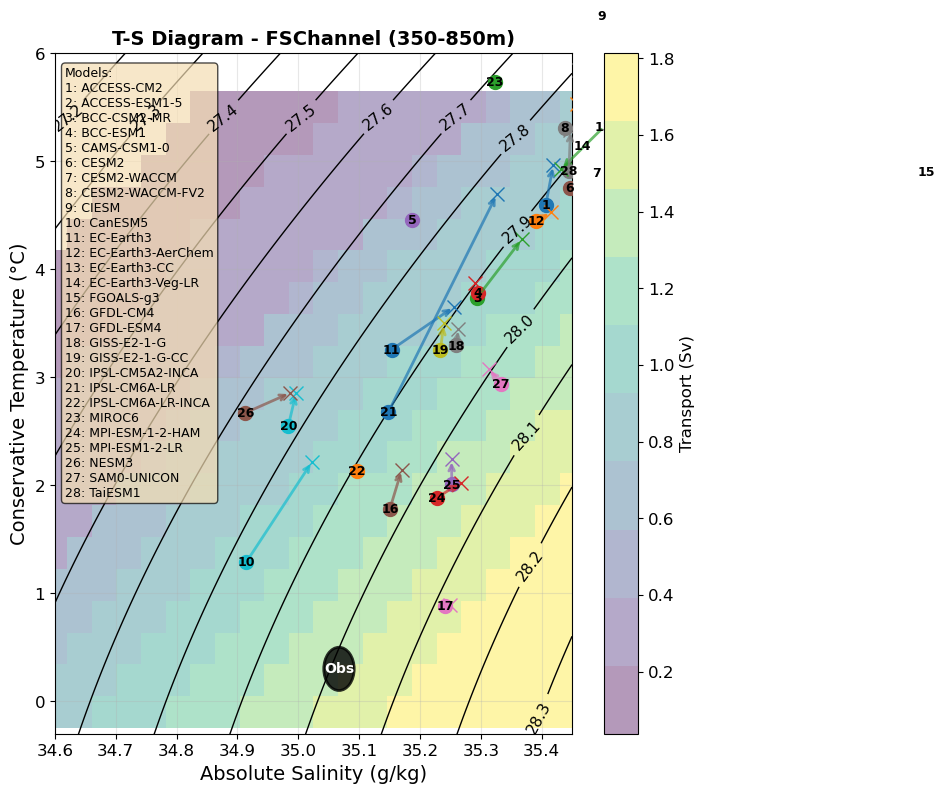

35.06693461579839


In [159]:
### FAROE SHETLAND CHANNEL Source water: Streamtube results and CMIP6 Sensitivity

import pickle
import numpy as np
import matplotlib.pyplot as plt
import gsw
from scipy import io as sio
from matplotlib.patches import Ellipse

# Load profiles
output_file = 'cmip6_profiles_4locations_all.pkl'
print(f"Loading profiles from {output_file}...")
with open(output_file, 'rb') as f:
    profiles = pickle.load(f)
print(f"Loaded {len(profiles)} models\n")

# Locations
locations = {
    'SPSide_DS': {'lat': 65.0, 'lon': 330.0},
    'SPSide_FSC': {'lat': 62, 'lon': 350.0},
    'DenStrait': {'lat': 67.5, 'lon': 334},
    'FSChannel': {'lat': 64, 'lon': 356}
}

# Load MATLAB data
mat_data = sio.loadmat('/Users/jaimepalter/Library/CloudStorage/OneDrive-UniversityofRhodeIsland/New Ideas/AMOC Lunch Bunch/FBC_transport_dataSiCTi.mat')
Si = mat_data['Si']
CTi = mat_data['CTi']
Transport = mat_data['T']

location = 'FSChannel'
lat = locations[location]['lat']
lon = locations[location]['lon']


def profile_SA_CT(data, model_name, lat, lon):
    """
    Return depth, absolute salinity (g/kg), and conservative temperature (degC)
    for one profile. Applies the MRI-ESM2-0 fill mask (800 m test) first because it seemed to use a fill value of 2°C.
    """
    pt = np.squeeze(data['thetao']).astype(float)     # potential temp (degC)
    sp = np.squeeze(data['so']).astype(float)         # practical salinity
    depth = np.squeeze(data['depth']).astype(float)   # m, positive down

    if model_name == 'MRI-ESM2-0':
        i800 = np.argmin(np.abs(depth - 800))
        if np.abs(pt[i800] - 2) <= 0.1:               # fill value, so drop profile
            pt = np.full_like(pt, np.nan)
            sp = np.full_like(sp, np.nan)

    p = gsw.p_from_z(-depth, lat) 
    SA = gsw.SA_from_SP(sp, p, lon % 360, lat)        # absolute salinity (g/kg)
    CT = gsw.CT_from_pt(SA, pt)                       # conservative temperature (degC)
    return depth, SA, CT


fig, ax = plt.subplots(figsize=(10, 8))

# === Transport CONTOURS (behind everything) ===
Transmean = np.squeeze(Transport[:, :, :200].mean(axis=2))
cmap_discrete = plt.cm.get_cmap('viridis', 10)
pcm = ax.pcolormesh(Si, CTi, Transmean / 1e6,
                    cmap=cmap_discrete,
                    alpha=0.4,
                    shading='auto',
                    zorder=0)

# === Potential density contours (sigma0, referenced to sea surface) ===
sal_range = np.linspace(34.4, 35.45, 100)     # absolute salinity (g/kg)
temp_range = np.linspace(-1, 6, 100)          # conservative temperature (degC)
Sal, Temp = np.meshgrid(sal_range, temp_range)
density = gsw.sigma0(Sal, Temp)

contours = ax.contour(Sal, Temp, density,
                      levels=np.arange(26, 28.5, 0.1),
                      colors='black', linewidths=1, zorder=2)
ax.clabel(contours, fontsize=11, fmt='%0.1f')

# Store early period data and model info
early_data = {}
model_list = []
model_counter = 1

# === Early period (circles) ===
for model_name, model_data in sorted(profiles.items()):
    if location not in model_data:
        continue
    try:
        data = model_data[location]['period1_1950-1969']
        depth, SA, CT = profile_SA_CT(data, model_name, lat, lon)

        mask = (depth >= 350) & (depth <= 850) & ~np.isnan(SA) & ~np.isnan(CT)
        if not np.any(mask):
            continue

        sal_mean = np.mean(SA[mask])
        temp_mean = np.mean(CT[mask])

        line = ax.plot(sal_mean, temp_mean, 'o',
                       linewidth=2, markersize=10, zorder=3)
        color = line[0].get_color()

        ax.text(sal_mean, temp_mean, str(model_counter),
                ha='center', va='center', fontsize=9, fontweight='bold',
                color='black', zorder=4)

        model_list.append((model_counter, model_name))
        early_data[model_name] = (sal_mean, temp_mean, color)
        model_counter += 1

    except Exception as e:
        print(f"{model_name} early period: {e}")

# === Late period (x) and arrows ===
for model_name, model_data in sorted(profiles.items()):
    if location not in model_data:
        continue
    try:
        data = model_data[location]['period2_1995-2014']
        depth, SA, CT = profile_SA_CT(data, model_name, lat, lon)

        mask = (depth >= 350) & (depth <= 850) & ~np.isnan(SA) & ~np.isnan(CT)
        if not np.any(mask):
            continue

        sal_mean = np.mean(SA[mask])
        temp_mean = np.mean(CT[mask])

        if model_name in early_data:
            sal_early, temp_early, color = early_data[model_name]

            ax.plot(sal_mean, temp_mean, 'x', color=color,
                    linewidth=3, markersize=10, zorder=3)

            ax.annotate('',
                        xy=(sal_mean, temp_mean),
                        xytext=(sal_early, temp_early),
                        arrowprops=dict(arrowstyle='->', lw=2, alpha=0.7, color=color),
                        zorder=3)

    except Exception as e:
        print(f"{model_name} late period: {e}")

ax.set_ylim(-0.3, 6)
ax.set_xlim(34.6, 35.45)
ax.set_ylabel('Conservative Temperature (°C)', fontsize=14)
ax.set_xlabel('Absolute Salinity (g/kg)', fontsize=14)
ax.set_title(f'T-S Diagram - {location} (350-850m)', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3, zorder=0)

# Observation region
obs_SA_est = gsw.SA_from_SP(34.9, 600, lon % 360, lat) 
obs_CT_est = gsw.CT_from_pt(obs_SA_est, 0.3)   
ellipse = Ellipse((obs_SA_est, obs_CT_est),
                  width=0.05,
                  height=0.4,
                  facecolor='black',
                  alpha=0.8,
                  edgecolor='black',
                  linewidth=2,
                  zorder=3)
ax.add_patch(ellipse)
ax.text(obs_SA_est,obs_CT_est, 'Obs', ha='center', va='center',
        fontsize=10, fontweight='bold', color='white', zorder=4)

# Model legend
legend_text = "Models:\n" + "\n".join([f"{num}: {name}" for num, name in model_list])
ax.text(0.02, 0.98, legend_text, transform=ax.transAxes,
        fontsize=9, verticalalignment='top',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.7))

ax.tick_params(axis='both', labelsize=12)
cbar = plt.colorbar(pcm, ax=ax)
cbar.set_label('Transport (Sv)', fontsize=12)
cbar.ax.tick_params(labelsize=12)


fig.savefig("Figure4b_FBC_TS.png", dpi=300)
plt.tight_layout()
plt.show()
print(obs_SA_est)

In [117]:
gsw.sigma0(34.95,1)

np.float64(27.873954530086166)

Loading profiles from cmip6_profiles_4locations_all.pkl...
Loaded 36 models

CAS-ESM2-0 early period: 'thetao'
MPI-ESM1-2-HR early period: 'so'
CAS-ESM2-0 late period: 'thetao'
MPI-ESM1-2-HR late period: 'so'


/var/folders/h1/j3p_b5ts7314ws9g_tynb4g80000gn/T/ipykernel_51045/4212470531.py:30: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_discrete = plt.cm.get_cmap('viridis', 10)


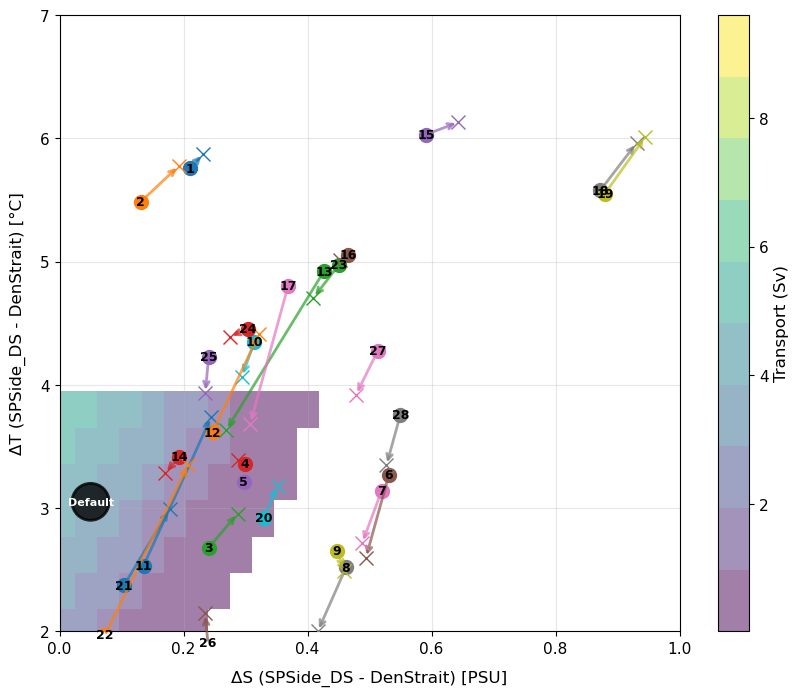

In [106]:
### DENMARK STRAIT PROPERTY DIFFERENCES: Streamtube results and CMIP6 Sensitivity 

import pickle
import numpy as np
import matplotlib.pyplot as plt
from scipy import io as sio

# Load profiles
output_file = 'cmip6_profiles_4locations_all.pkl'
print(f"Loading profiles from {output_file}...")
with open(output_file, 'rb') as f:
    profiles = pickle.load(f)

print(f"Loaded {len(profiles)} models\n")

# Load MATLAB data
mat_data = sio.loadmat('/Users/jaimepalter/Library/CloudStorage/OneDrive-UniversityofRhodeIsland/New Ideas/AMOC Lunch Bunch/transport_data.mat')

Si = mat_data['Si']
CTi = mat_data['CTi']
Transport = mat_data['T']

loc1 = 'SPSide_DS'
loc2 = 'DenStrait'

fig, ax = plt.subplots(figsize=(10, 8))

# === ADD Transport CONTOURS FIRST (behind everything) ===
Transmean = np.squeeze(Transport[:, :, :200].mean(axis=2))
cmap_discrete = plt.cm.get_cmap('viridis', 10)
pcm = ax.pcolormesh(34.9-Si, 3.7-CTi, Transmean/1e6, 
                    cmap=cmap_discrete,
                    alpha=0.5,
                    shading='auto',
                    zorder=0)

# Add colorbar
cbar = plt.colorbar(pcm, ax=ax)
cbar.set_label('Transport (Sv)', fontsize=12)
cbar.ax.tick_params(labelsize=12)


# Store early period data and model info
early_data = {}
model_list = []
model_counter = 1

# Plot early period (circles)
for model_name, model_data in sorted(profiles.items()):
    if loc1 not in model_data or loc2 not in model_data:
        continue
    
    try:
        # Get data for both locations
        data1 = model_data[loc1]['period1_1950-1969']
        data2 = model_data[loc2]['period1_1950-1969']
        
        depth1 = data1['depth']
        temp1 = np.squeeze(data1['thetao'])
        sal1 = np.squeeze(data1['so'])
        
        depth2 = data2['depth']
        temp2 = np.squeeze(data2['thetao'])
        sal2 = np.squeeze(data2['so'])
        
        # Average for the depth of the supolar side (mask 1) and overflow source (mask 2)
        mask1 = (depth1 >= 700) & (depth1 <= 1000) & (~np.isnan(temp1)) & (~np.isnan(sal1))
        mask2 = (depth2 >= 300) & (depth2 <= 700) & (~np.isnan(temp2)) & (~np.isnan(sal2))
        
        if not (np.any(mask1) and np.any(mask2)):
            continue
        
        temp1_mean = np.nanmean(temp1[mask1])
        sal1_mean = np.nanmean(sal1[mask1])
        
        temp2_mean = np.nanmean(temp2[mask2])
        sal2_mean = np.nanmean(sal2[mask2])
        
        # Calculate difference (SPSide_DS - DenStrait)
        delta_temp = temp1_mean - temp2_mean
        delta_sal = sal1_mean - sal2_mean
        
        # Plot circle
        line = ax.plot(delta_sal, delta_temp, 'o', 
                      linewidth=2, markersize=10, zorder=3)
        color = line[0].get_color()
        
        # Add number inside circle
        ax.text(delta_sal, delta_temp, str(model_counter), 
               ha='center', va='center', fontsize=9, fontweight='bold', 
               color='black', zorder=4)
        
        model_list.append((model_counter, model_name))
        early_data[model_name] = (delta_sal, delta_temp, color)
        model_counter += 1
        
    except Exception as e:
        print(f"{model_name} early period: {e}")

# Plot late period (x) and draw arrows
for model_name, model_data in sorted(profiles.items()):
    if loc1 not in model_data or loc2 not in model_data:
        continue
    
    try:
        # Get data for both locations
        data1 = model_data[loc1]['period2_1995-2014']
        data2 = model_data[loc2]['period2_1995-2014']
        
        depth1 = data1['depth']
        temp1 = np.squeeze(data1['thetao'])
        sal1 = np.squeeze(data1['so'])
        
        depth2 = data2['depth']
        temp2 = np.squeeze(data2['thetao'])
        sal2 = np.squeeze(data2['so'])
        
        # Average from 300-700m for both locations
        mask1 = (depth1 >= 700) & (depth1 <= 1000) & (~np.isnan(temp1)) & (~np.isnan(sal1))
        mask2 = (depth2 >= 300) & (depth2 <= 700) & (~np.isnan(temp2)) & (~np.isnan(sal2))
        
        if not (np.any(mask1) and np.any(mask2)):
            continue
        
        temp1_mean = np.nanmean(temp1[mask1])
        sal1_mean = np.nanmean(sal1[mask1])
        
        temp2_mean = np.nanmean(temp2[mask2])
        sal2_mean = np.nanmean(sal2[mask2])
        
        # Calculate difference (SPSide_DS - DenStrait)
        delta_temp = temp1_mean - temp2_mean
        delta_sal = sal1_mean - sal2_mean
        
        if model_name in early_data:
            sal_early, temp_early, color = early_data[model_name]
            
            # Plot late data with X marker
            ax.plot(delta_sal, delta_temp, 'x', color=color, 
                   linewidth=3, markersize=10, zorder=3)
            
            # Draw arrow from early to late
            ax.annotate('', 
                       xy=(delta_sal, delta_temp),
                       xytext=(sal_early, temp_early),
                       arrowprops=dict(arrowstyle='->', lw=2, alpha=0.7, color=color),
                       zorder=3)
        
    except Exception as e:
        print(f"{model_name} late period: {e}")

ax.set_ylim(2, 7)
ax.set_xlim(0, 1)
ax.set_ylabel('ΔT (SPSide_DS - DenStrait) [°C]', fontsize=12, labelpad=10)
ax.set_xlabel('ΔS (SPSide_DS - DenStrait) [PSU]', fontsize=12, labelpad=10)
#ax.set_title(f'T-S Difference: {loc1} minus {loc2}', fontsize=14, fontweight='bold')
# Set tick label sizes
ax.tick_params(axis='both', labelsize=12)
cbar.ax.tick_params(labelsize=12)
ax.grid(True, alpha=0.3, zorder=0)

ellipse = Ellipse((34.9-34.85,3.7- 0.65),
                  width=0.06,
                  height=0.3,
                  facecolor='black', 
                  alpha=0.8,
                  edgecolor='black',
                  linewidth=2,
                  zorder=3)
#Comment out the observational ellipse, since I don't have a great comparison on the subpolar side to pair
ax.add_patch(ellipse)
ax.text(34.9-34.85,3.7- 0.65, 'Default', ha='center', va='center', 
       fontsize=8, fontweight='bold', color='white', zorder=4)

# Create legend with model numbers
#legend_text = "Models:\n" + "\n".join([f"{num}: {name}" for num, name in model_list])
#ax.text(0.02, 0.98, legend_text, transform=ax.transAxes, 
 #      fontsize=8, verticalalignment='top',
   # bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.7))

#plt.tight_layout()
plt.show()

fig.savefig("DS_TS_diff_supp.png", dpi=300, bbox_inches="tight")


Loading profiles from cmip6_profiles_4locations_all.pkl...
Loaded 36 models

CAS-ESM2-0 early period: 'thetao'
MPI-ESM1-2-HR early period: 'so'


/var/folders/h1/j3p_b5ts7314ws9g_tynb4g80000gn/T/ipykernel_51045/2538848881.py:30: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_discrete = plt.cm.get_cmap('viridis', 10)


CAS-ESM2-0 late period: 'thetao'
MPI-ESM1-2-HR late period: 'so'


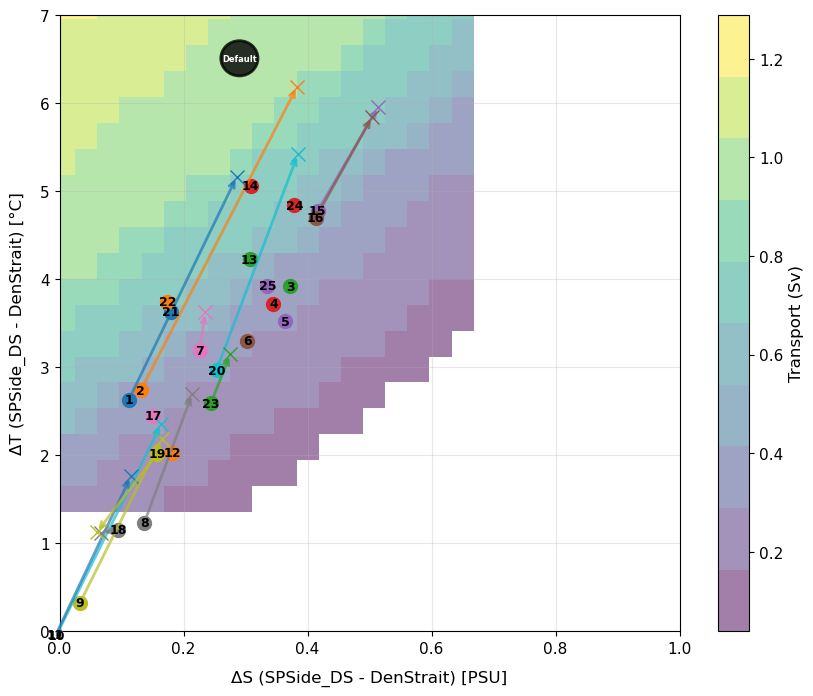

In [109]:
### FAROE SHETLAND CHANNEL PROPERTY DIFFERENCES: Streamtube results and CMIP6 Sensitivity 

import pickle
import numpy as np
import matplotlib.pyplot as plt
from scipy import io as sio

# Load profiles
output_file = 'cmip6_profiles_4locations_all.pkl'
print(f"Loading profiles from {output_file}...")
with open(output_file, 'rb') as f:
    profiles = pickle.load(f)

print(f"Loaded {len(profiles)} models\n")

# Load MATLAB data
mat_data = sio.loadmat('/Users/jaimepalter/Library/CloudStorage/OneDrive-UniversityofRhodeIsland/New Ideas/AMOC Lunch Bunch/FBC_transportSiCTi.mat')

Si = mat_data['Si']
CTi = mat_data['CTi']
Transport = mat_data['Transport']

loc1 = 'SPSide_FSC'
loc2 = 'FSChannel'

fig, ax = plt.subplots(figsize=(10, 8))

# === ADD Transport CONTOURS FIRST (behind everything) ===
Transmean = np.squeeze(Transport[:, :, :200].mean(axis=2))
cmap_discrete = plt.cm.get_cmap('viridis', 10)
pcm = ax.pcolormesh(35.15-Si, 7-CTi, Transmean/1e6, 
                    cmap=cmap_discrete,
                    alpha=0.5,
                    shading='auto',
                    zorder=0)

# Add colorbar
cbar = plt.colorbar(pcm, ax=ax, label='Transport (Sv)')
cbar.set_label('Transport (Sv)', fontsize=12)
#cbar.ax.tick_params(labelsize=12)

# Store early period data and model info
early_data = {}
model_list = []
model_counter = 1

# Plot early period (circles)
for model_name, model_data in sorted(profiles.items()):
    if loc1 not in model_data or loc2 not in model_data:
        continue
    
    try:
        # Get data for both locations
        data1 = model_data[loc1]['period1_1950-1969']
        data2 = model_data[loc2]['period1_1950-1969']
        
        depth1 = data1['depth']
        temp1 = np.squeeze(data1['thetao'])
        sal1 = np.squeeze(data1['so'])
        
        depth2 = data2['depth']
        temp2 = np.squeeze(data2['thetao'])
        sal2 = np.squeeze(data2['so'])
        
        # Average at 
        mask1 = (depth1 >= 700) & (depth1 <= 1000) & (~np.isnan(temp1)) & (~np.isnan(sal1))
        mask2 = (depth2 >= 350) & (depth2 <= 800) & (~np.isnan(temp2)) & (~np.isnan(sal2))
        
        if not (np.any(mask1) and np.any(mask2)):
            continue
        
        temp1_mean = np.nanmean(temp1[mask1])
        sal1_mean = np.nanmean(sal1[mask1])
        
        temp2_mean = np.nanmean(temp2[mask2])
        sal2_mean = np.nanmean(sal2[mask2])
        
        # Calculate difference (SPSide_FSC - FS_Channel)
        delta_temp = temp1_mean - temp2_mean
        delta_sal = sal1_mean - sal2_mean
        
        # Plot circle
        line = ax.plot(delta_sal, delta_temp, 'o', 
                      linewidth=2, markersize=10, zorder=3)
        color = line[0].get_color()
        
        # Add number inside circle
        ax.text(delta_sal, delta_temp, str(model_counter), 
               ha='center', va='center', fontsize=9, fontweight='bold', 
               color='black', zorder=4)
        
        model_list.append((model_counter, model_name))
        early_data[model_name] = (delta_sal, delta_temp, color)
        model_counter += 1
        
    except Exception as e:
        print(f"{model_name} early period: {e}")

# Plot late period (x) and draw arrows
for model_name, model_data in sorted(profiles.items()):
    if loc1 not in model_data or loc2 not in model_data:
        continue
    
    try:
        # Get data for both locations
        data1 = model_data[loc1]['period2_1995-2014']
        data2 = model_data[loc2]['period2_1995-2014']
        
        depth1 = data1['depth']
        temp1 = np.squeeze(data1['thetao'])
        sal1 = np.squeeze(data1['so'])
        
        depth2 = data2['depth']
        temp2 = np.squeeze(data2['thetao'])
        sal2 = np.squeeze(data2['so'])
        
        # Average from 300-700m for both locations
        mask1 = (depth1 >= 850) & (depth1 <= 1000) & (~np.isnan(temp1)) & (~np.isnan(sal1))
        mask2 = (depth2 >= 650) & (depth2 <= 850) & (~np.isnan(temp2)) & (~np.isnan(sal2))
        
        if not (np.any(mask1) and np.any(mask2)):
            continue
        
        temp1_mean = np.nanmean(temp1[mask1])
        sal1_mean = np.nanmean(sal1[mask1])
        
        temp2_mean = np.nanmean(temp2[mask2])
        sal2_mean = np.nanmean(sal2[mask2])
        
        # Calculate difference (SPSide_DS - DenStrait)
        delta_temp = temp1_mean - temp2_mean
        delta_sal = sal1_mean - sal2_mean
        
        if model_name in early_data:
            sal_early, temp_early, color = early_data[model_name]
            
            # Plot late data with X marker
            ax.plot(delta_sal, delta_temp, 'x', color=color, 
                   linewidth=3, markersize=10, zorder=3)
            
            # Draw arrow from early to late
            ax.annotate('', 
                       xy=(delta_sal, delta_temp),
                       xytext=(sal_early, temp_early),
                       arrowprops=dict(arrowstyle='->', lw=2, alpha=0.7, color=color),
                       zorder=3)
        
    except Exception as e:
        print(f"{model_name} late period: {e}")

ax.set_ylim(0, 7)
ax.set_xlim(0, 1)
ax.set_ylabel('ΔT (SPSide_DS - DenStrait) [°C]', fontsize=12, labelpad=10)
ax.set_xlabel('ΔS (SPSide_DS - DenStrait) [PSU]', fontsize=12, labelpad=10)
#ax.set_title(f'T-S Difference: {loc1} minus {loc2}', fontsize=14, fontweight='bold')
# Set tick label sizes
ax.tick_params(axis='both', labelsize=12)
cbar.ax.tick_params(labelsize=12)
ax.grid(True, alpha=0.3, zorder=0)

ellipse = Ellipse((35.15-34.86,7-0.49),
                  width=0.06,
                  height=0.4,
                  facecolor='black', 
                  alpha=0.8,
                  edgecolor='black',
                  linewidth=2,
                  zorder=3)
# Comment observational ellipse, since I don't have a great time series to compare on the subpolar side
ax.add_patch(ellipse)
ax.text(35.15-34.86,7-0.49, 'Default', ha='center', va='center', 
      fontsize=6, fontweight='bold', color='white', zorder=4)

# Create legend with model numbers
legend_text = "Models:\n" + "\n".join([f"{num}: {name}" for num, name in model_list])
#ax.text(0.02, 0.98, legend_text, transform=ax.transAxes, 
 #      fontsize=8, verticalalignment='top',
   # bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.7))

#plt.tight_layout()
plt.show()

fig.savefig("DS_TS_diff_supp.png", dpi=300, bbox_inches="tight")



In [108]:
pwd

'/Users/jaimepalter'